Підготовка

In [1]:
import os, re, glob, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

os.makedirs("results/figures", exist_ok=True)

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"не знайшов {name}: перевір Add Input"
    return hits[0]

tr = pd.read_csv(find("train_transaction.csv"))
idn = pd.read_csv(find("train_identity.csv"))
for c in tr.select_dtypes("float64").columns:
    tr[c] = tr[c].astype("float32")
df = tr.merge(idn, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"])
df["day"] = (df["TransactionDT"] // 86400).astype(int)
df["week"] = df["day"] // 7
del tr

N = len(df)
TRAIN_W, VAL_W, TEST_W = (0, 17), (18, 21), (22, 26)
inw = lambda r: ((df.week >= r[0]) & (df.week <= r[1])).values
m_tr, m_va, m_te = inw(TRAIN_W), inw(VAL_W), inw(TEST_W)
assert (m_tr | m_va | m_te).all() and not (m_tr & m_va).any() and not (m_va & m_te).any()
assert (m_tr.sum(), m_va.sum(), m_te.sum()) == (431125, 77090, 82325)

ts, tid = df.TransactionDT.values, df.TransactionID.values
order = np.lexsort((tid, ts))
rank = np.empty(N, dtype=np.int64); rank[order] = np.arange(N)
y = df.isFraud.values
assert y.sum() == 20663

X = df.drop(columns=["TransactionID", "isFraud", "TransactionDT", "day", "week"]).copy()
X["hour"] = (df.TransactionDT // 3600) % 24
X["weekday"] = (df.TransactionDT // 86400) % 7
X["has_identity"] = X["has_identity"].astype("int8")
for c in X.select_dtypes(include=["object", "category"]).columns:
    codes, _ = pd.factorize(X[c])
    X[c] = np.where(codes == -1, np.nan, codes).astype("float32")
spw = (y[m_tr] == 0).sum() / (y[m_tr] == 1).sum()

def metrics(y_true, p):
    k = int(y_true.sum()); o = np.argsort(-p)
    top1 = o[: max(1, int(0.01 * len(y_true)))]
    return {"pr_auc": average_precision_score(y_true, p),
            "roc_auc": roc_auc_score(y_true, p),
            "recall@k": y_true[o[:k]].sum() / k,
            "precision@1%": y_true[top1].mean(),
            "base_rate": y_true.mean()}

major = int(xgb.__version__.split(".")[0])
DEV = dict(tree_method="hist", device="cuda") if major >= 2 else dict(tree_method="gpu_hist")

def run_xgb_X(Xf, seed):
    m = XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                      eval_metric="aucpr", early_stopping_rounds=50,
                      random_state=seed, **DEV)
    m.fit(Xf[m_tr], y[m_tr], eval_set=[(Xf[m_va], y[m_va])], verbose=False)
    r = metrics(y[m_te], m.predict_proba(Xf[m_te])[:, 1])
    r.update(seed=seed, best_iter=m.best_iteration, val_aucpr=m.best_score)
    return r, m

print("готово:", X.shape, "| xgboost", xgb.__version__)

готово: (590540, 434) | xgboost 3.4.1


Ознаки з відкладених міток + перевірка на витік

In [3]:
KEYS = {"c1": ["card1"], "u2": ["card1", "addr1"],
        "u3": ["card1", "addr1", "P_emaildomain"]}
DELAYS = (7, 14, 30)

def delayed_label_feats(cols):
    valid = df[cols].notna().all(axis=1).values
    idx = np.flatnonzero(valid)
    out = {"nprior": np.full(N, np.nan, "float32")}
    for dl in DELAYS:
        out[f"nk{dl}"] = np.full(N, np.nan, "float32")   # скільки сусідів з відомою міткою
        out[f"fk{dl}"] = np.full(N, np.nan, "float32")   # скільки з них фрод
    sub = df.loc[valid, cols]
    for pos in sub.groupby(cols, sort=False).indices.values():
        rows = idx[pos]
        rows = rows[np.argsort(rank[rows], kind="stable")]     # за часом
        tt, ff = ts[rows], y[rows]
        cs = np.concatenate([[0], np.cumsum(ff)])
        a = np.searchsorted(tt, tt, side="left")               # усі раніші
        out["nprior"][rows] = a
        for dl in DELAYS:
            k = np.minimum(np.searchsorted(tt, tt - dl * 86400, side="right"), a)
            out[f"nk{dl}"][rows] = k
            out[f"fk{dl}"][rows] = cs[k]
    return out

t0 = time.time(); LF = {}
for rel, cols in KEYS.items():
    for k, v in delayed_label_feats(cols).items():
        LF[f"{rel}_{k}"] = v
    print(rel, "готово,", round(time.time() - t0), "с", flush=True)
LF = pd.DataFrame(LF)
for rel in KEYS:
    for dl in DELAYS:
        nk, fk = LF[f"{rel}_nk{dl}"], LF[f"{rel}_fk{dl}"]
        LF[f"{rel}_rate{dl}"] = (fk / nk.where(nk > 0)).astype("float32")

# --- перевірка на витік: повний перерахунок «в лоб» для випадкових рядків ---
A = {c: df[c].values for c in {"card1", "addr1", "P_emaildomain"}}
rng = np.random.default_rng(0); bad = 0; checked = 0
for rel in KEYS:
    cols = KEYS[rel]
    cand = np.flatnonzero(df[cols].notna().all(axis=1).values)
    for i in rng.choice(cand, 100, replace=False):
        same = np.ones(N, dtype=bool)
        for c in cols:
            same &= (A[c] == A[c][i])
        if int((same & (ts < ts[i])).sum()) != int(LF[f"{rel}_nprior"].values[i]): bad += 1
        for dl in DELAYS:
            known = same & (ts <= ts[i] - dl * 86400)
            if (int(known.sum()) != int(LF[f"{rel}_nk{dl}"].values[i]) or
                    int(y[known].sum()) != int(LF[f"{rel}_fk{dl}"].values[i])):
                bad += 1
        checked += 1
print(f"перевірено рядків: {checked}, розбіжностей: {bad}")
assert bad == 0

# допоміжна перевірка: відомих сусідів не більше, ніж раніших (лише там, де є ключ)
for rel in KEYS:
    for dl in DELAYS:
        nk, npr = LF[f"{rel}_nk{dl}"], LF[f"{rel}_nprior"]
        ok = npr.notna()
        assert (nk[ok] <= npr[ok]).all(), f"{rel} δ={dl}: відомих сусідів більше, ніж раніших"
        assert nk[~ok].isna().all(), f"{rel} δ={dl}: є значення там, де немає ключа"
print("перевірки на витік пройдено")

c1 готово, 1 с
u2 готово, 2 с
u3 готово, 6 с
перевірено рядків: 300, розбіжностей: 0
перевірки на витік пройдено


Скільки рядків мають відомих сусідів і наскільки це інформативно

In [4]:
cov = []
for rel in KEYS:
    for dl in DELAYS:
        has = (LF[f"{rel}_nk{dl}"] > 0).values
        hasf = (LF[f"{rel}_fk{dl}"] > 0).values
        for sp, m in [("train", m_tr), ("val", m_va), ("test", m_te)]:
            cov.append({"відношення": rel, "δ": dl, "частина": sp,
                        "є відомі сусіди, %": round(has[m].mean() * 100, 1),
                        "є відомий фрод-сусід, %": round(hasf[m].mean() * 100, 1)})
cov = pd.DataFrame(cov)
display(cov[cov["частина"] == "test"].drop(columns="частина"))
cov.to_csv("results/ieee_cis_delayed_label_coverage.csv", index=False)

sig = []
for rel in KEYS:
    for dl in DELAYS:
        fk = LF[f"{rel}_fk{dl}"].values; nk = LF[f"{rel}_nk{dl}"].values
        for sp, m in [("val", m_va), ("test", m_te)]:
            a = m & (fk > 0)               # є відомий фрод-сусід
            b = m & (nk > 0) & (fk == 0)   # сусіди відомі, і всі чесні
            sig.append({"відношення": rel, "δ": dl, "частина": sp,
                        "рядків (фрод-сусід)": int(a.sum()),
                        "частка фроду, % (фрод-сусід)": round(y[a].mean() * 100, 1),
                        "рядків (сусіди чесні)": int(b.sum()),
                        "частка фроду, % (сусіди чесні)": round(y[b].mean() * 100, 1),
                        "частка фроду в частині, %": round(y[m].mean() * 100, 1)})
sig = pd.DataFrame(sig)
display(sig[sig["частина"] == "test"].drop(columns="частина"))
sig.to_csv("results/ieee_cis_delayed_label_signal.csv", index=False)

,відношення,δ,"є відомі сусіди, %","є відомий фрод-сусід, %"
2,c1,7,99.0,76.1
5,c1,14,98.9,75.7
8,c1,30,98.7,75.0
11,u2,7,85.9,43.2
14,u2,14,85.7,42.7
17,u2,30,85.2,41.8
20,u3,7,63.2,20.4
23,u3,14,62.7,20.0
26,u3,30,61.8,19.4


,відношення,δ,рядків (фрод-сусід),"частка фроду, % (фрод-сусід)",рядків (сусіди чесні),"частка фроду, % (сусіди чесні)","частка фроду в частині, %"
1,c1,7,62617,4.2,18864,1.1,3.5
3,c1,14,62347,4.1,19064,1.3,3.5
5,c1,30,61741,4.1,19552,1.4,3.5
7,u2,7,35601,3.2,35124,1.3,3.5
9,u2,14,35173,3.1,35375,1.4,3.5
11,u2,30,34383,3.1,35761,1.4,3.5
13,u3,7,16800,4.0,35210,1.2,3.5
15,u3,14,16500,3.7,35088,1.3,3.5
17,u3,30,15940,3.7,34908,1.3,3.5


Чотири варіанти + два контролі, спершу по одному seed

In [5]:
cnt = [f"{r}_nprior" for r in KEYS]
lab = lambda dl: [f"{r}_{k}{dl}" for r in KEYS for k in ("nk", "fk", "rate")]
VAR_COLS = {"base": [], "+cnt": cnt}
for dl in DELAYS:
    VAR_COLS[f"+lab δ={dl}"] = cnt + lab(dl)

def make_X(name):
    cols = VAR_COLS[name]
    return pd.concat([X, LF[cols]], axis=1) if cols else X

res = []
for name in VAR_COLS:
    t0 = time.time()
    r, _ = run_xgb_X(make_X(name), 0)
    r["variant"] = name; res.append(r)
    print(f"{name:12s} PR-AUC {r['pr_auc']:.4f} | ROC-AUC {r['roc_auc']:.4f} | "
          f"P@1% {r['precision@1%']:.3f} | дерев {r['best_iter']} | {time.time()-t0:.0f} с", flush=True)

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [14:32:23] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


base         PR-AUC 0.4998 | ROC-AUC 0.8803 | P@1% 0.883 | дерев 801 | 42 с
+cnt         PR-AUC 0.5148 | ROC-AUC 0.8929 | P@1% 0.878 | дерев 421 | 30 с
+lab δ=7     PR-AUC 0.5617 | ROC-AUC 0.9091 | P@1% 0.889 | дерев 525 | 35 с
+lab δ=14    PR-AUC 0.5594 | ROC-AUC 0.9140 | P@1% 0.883 | дерев 302 | 27 с
+lab δ=30    PR-AUC 0.5530 | ROC-AUC 0.9079 | P@1% 0.896 | дерев 293 | 26 с


Решта seed

In [6]:
for name in VAR_COLS:
    Xf = make_X(name)
    for sd in range(1, 5):
        r, _ = run_xgb_X(Xf, sd)
        r["variant"] = name; res.append(r)
        print(name, sd, round(float(r["pr_auc"]), 4), flush=True)
res = pd.DataFrame(res)
res.to_csv("results/ieee_cis_delayed_label_results.csv", index=False)
res.groupby("variant")[["pr_auc", "roc_auc", "recall@k", "precision@1%"]].agg(["mean", "std"]).round(3)

base 1 0.5064
base 2 0.5059
base 3 0.5064
base 4 0.5068
+cnt 1 0.5015
+cnt 2 0.5048
+cnt 3 0.4912
+cnt 4 0.5096
+lab δ=7 1 0.5775
+lab δ=7 2 0.579
+lab δ=7 3 0.5701
+lab δ=7 4 0.5746
+lab δ=14 1 0.5679
+lab δ=14 2 0.5608
+lab δ=14 3 0.556
+lab δ=14 4 0.5676
+lab δ=30 1 0.5517
+lab δ=30 2 0.5512
+lab δ=30 3 0.5553
+lab δ=30 4 0.5489


pr_auc        roc_auc        recall@k        precision@1%       
            mean    std    mean    std     mean    std         mean    std
variant                                                                   
+cnt       0.504  0.009   0.887  0.005    0.491  0.005        0.872  0.006
+lab δ=14  0.562  0.005   0.912  0.004    0.543  0.004        0.887  0.006
+lab δ=30  0.552  0.002   0.907  0.004    0.536  0.003        0.886  0.008
+lab δ=7   0.573  0.007   0.918  0.006    0.553  0.006        0.893  0.003
base       0.505  0.003   0.886  0.005    0.487  0.006        0.876  0.007

Рисунки

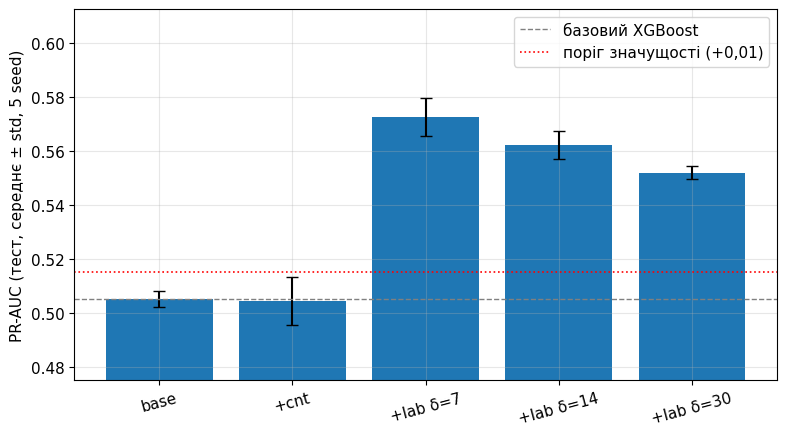

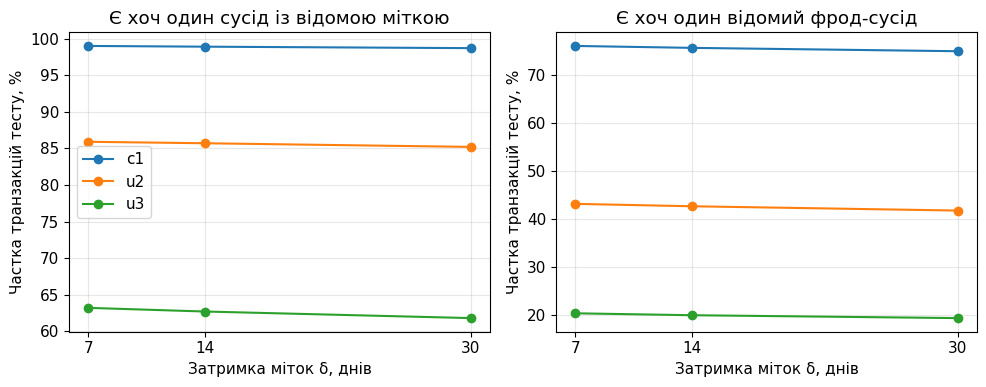

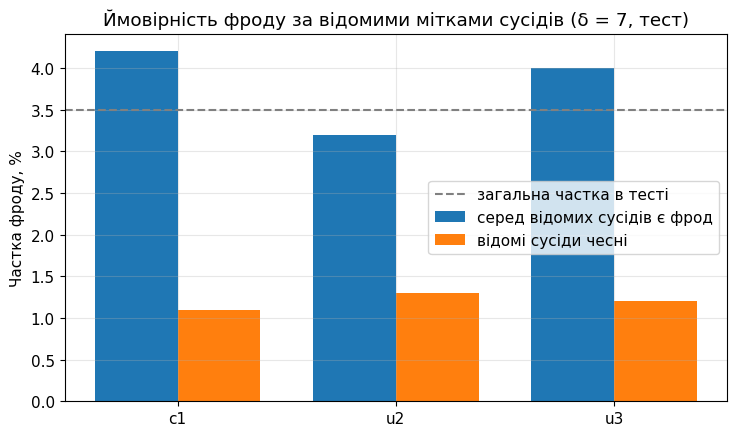

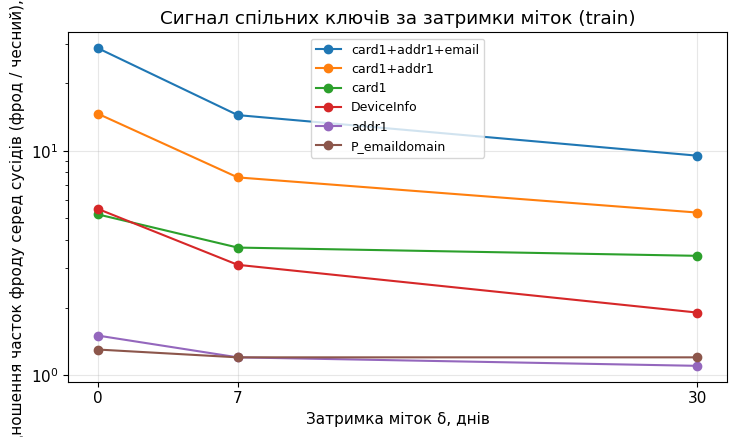

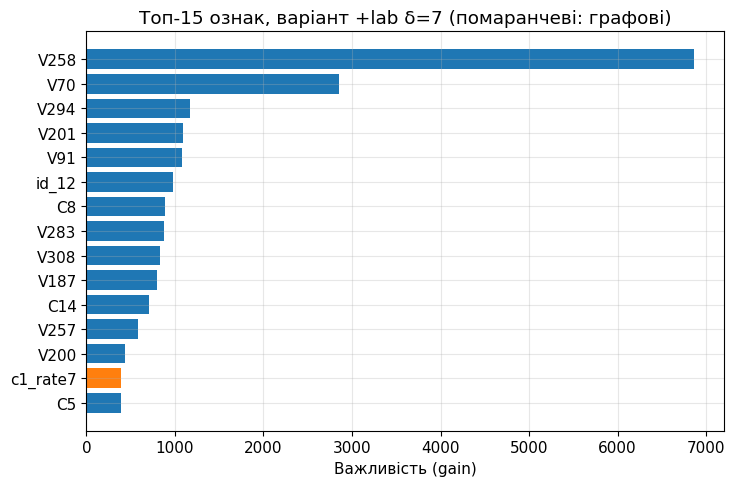

In [7]:
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.3})
order_v = list(VAR_COLS)

# Рис. A: PR-AUC за варіантами
s = res.groupby("variant")["pr_auc"].agg(["mean", "std"]).reindex(order_v)
b = s.loc["base", "mean"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(len(s)), s["mean"], yerr=s["std"], capsize=4)
ax.axhline(b, color="gray", ls="--", lw=1, label="базовий XGBoost")
ax.axhline(b + 0.01, color="red", ls=":", lw=1.2, label="поріг значущості (+0,01)")
ax.set_xticks(range(len(s))); ax.set_xticklabels(order_v, rotation=15)
ax.set_ylabel("PR-AUC (тест, середнє ± std, 5 seed)")
ax.set_ylim(b - 0.03, max(s["mean"].max(), b + 0.01) + 0.04)
ax.legend(); plt.tight_layout()
plt.savefig("results/figures/ieee_cis_delayed_label_prauc.png", dpi=200); plt.show()

# Рис. B: покриття залежно від затримки (тест)
t = cov[cov["частина"] == "test"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for rel in KEYS:
    q = t[t["відношення"] == rel]
    ax[0].plot(q["δ"], q["є відомі сусіди, %"], marker="o", label=rel)
    ax[1].plot(q["δ"], q["є відомий фрод-сусід, %"], marker="o", label=rel)
ax[0].set_title("Є хоч один сусід із відомою міткою"); ax[1].set_title("Є хоч один відомий фрод-сусід")
for a in ax: a.set_xlabel("Затримка міток δ, днів"); a.set_ylabel("Частка транзакцій тесту, %"); a.set_xticks(DELAYS)
ax[0].legend(); plt.tight_layout()
plt.savefig("results/figures/ieee_cis_label_coverage.png", dpi=200); plt.show()

# Рис. C: імовірність фроду залежно від того, що відомо про сусідів (δ = 7, тест)
q = sig[(sig["частина"] == "test") & (sig["δ"] == 7)].set_index("відношення").loc[list(KEYS)]
x = np.arange(len(q)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(x - w/2, q["частка фроду, % (фрод-сусід)"], w, label="серед відомих сусідів є фрод")
ax.bar(x + w/2, q["частка фроду, % (сусіди чесні)"], w, label="відомі сусіди чесні")
ax.axhline(q["частка фроду в частині, %"].iloc[0], color="gray", ls="--", label="загальна частка в тесті")
ax.set_xticks(x); ax.set_xticklabels(q.index)
ax.set_ylabel("Частка фроду, %"); ax.set_title("Ймовірність фроду за відомими мітками сусідів (δ = 7, тест)")
ax.legend(); plt.tight_layout()
plt.savefig("results/figures/ieee_cis_label_signal_test.png", dpi=200); plt.show()

# Рис. D: сигнал ключів за затримкою міток (дані комірки D на train)
sig_tbl = {"card1+addr1+email": [28.6, 14.4, 9.5], "card1+addr1": [14.6, 7.6, 5.3],
           "card1": [5.2, 3.7, 3.4], "DeviceInfo": [5.5, 3.1, 1.9],
           "addr1": [1.5, 1.2, 1.1], "P_emaildomain": [1.3, 1.2, 1.2]}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for k, v in sig_tbl.items():
    ax.plot([0, 7, 30], v, marker="o", label=k)
ax.set_yscale("log"); ax.set_xticks([0, 7, 30])
ax.set_xlabel("Затримка міток δ, днів"); ax.set_ylabel("Відношення часток фроду серед сусідів (фрод / чесний), разів")
ax.set_title("Сигнал спільних ключів за затримки міток (train)")
ax.legend(fontsize=9); plt.tight_layout()
plt.savefig("results/figures/ieee_cis_signal_vs_delay.png", dpi=200); plt.show()

# Рис. E: важливість ознак у найкращому варіанті
best = res.groupby("variant")["pr_auc"].mean().idxmax()
_, mdl = run_xgb_X(make_X(best), 0)
imp = pd.Series(mdl.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 5))
colors = ["tab:orange" if re.match(r"^(c1|u2|u3)_", n) else "tab:blue" for n in imp.index]
ax.barh(imp.index, imp.values, color=colors)
ax.set_xlabel("Важливість (gain)"); ax.set_title(f"Топ-15 ознак, варіант {best} (помаранчеві: графові)")
plt.tight_layout(); plt.savefig("results/figures/ieee_cis_delayed_label_importance.png", dpi=200); plt.show()
imp[::-1].round(1).to_csv("results/ieee_cis_delayed_label_importance.csv")